# Does an unmodelled detector PSF explain the code residue?

A controlled simulation. We know the truth, so there is nothing to argue about.

The real pipeline has `psf_sigma=0.0` everywhere, while the detector certainly blurs. On real
data we cannot separate that from the twenty other things that could be wrong. Here we can:
generate NFP data **with** a PSF, reconstruct **without** one, carry the result into an HT-style
flat field, and see whether code residue appears. Then do it again reconstructing **with** the
correct PSF as a control.

If the no-PSF arm shows residue and the control arm is clean, PSF mismatch is sufficient to
explain what we see on AtomiumS2_coded. If both are clean, it is not the cause and we stop
chasing it.

Geometry and the blur are the real AtomiumS2_coded numbers. Only the detector size is reduced,
which preserves the Fresnel number per pixel and so the physics that matters here.

In [1]:
import numpy as np, cupy as cp, matplotlib.pyplot as plt
from types import SimpleNamespace
from mpi4py import MPI
from holotomocupy.propagation import Propagation
from holotomocupy.psf import psf_taps, psf_blur
from holotomocupy.rec_nfp_coded_mpi import RecNFPCoded
%matplotlib inline
import matplotlib as mpl
mpl.rcParams.update({'image.interpolation': 'none', 'image.resample': False, 'figure.dpi': 110})

# --- the real AtomiumS2_coded geometry -------------------------------------------------------
ENERGY   = 33.35          # keV
DET_PX   = 3.03751e-6     # m
FDD      = 1.28           # m
Z1C      = -17.75e-3      # m, coded aperture (upstream of the focus)
Z1       = 2.95e-3        # m, sample

WAVELEN   = 1.24e-9 / ENERGY
VOX_NFP   = abs(DET_PX * Z1C / FDD)              # 42.12 nm, the NFP frame
DIST_NFP  = Z1C * (FDD - Z1C) / FDD              # -17.996 mm
VOX_HT    = DET_PX * Z1 / FDD                    # 7.0005 nm, the HT sample frame
DIST_HT   = Z1 * (FDD - Z1) / FDD                # 2.9432 mm
DIST_CODE = (Z1 - Z1C) * Z1 / Z1C                # -3.4403 mm

# --- the experiment --------------------------------------------------------------------------
PSF_TRUE  = 1.2           # detector px. Blurs the SIMULATED data. The advisor's Y350c value.
N         = 512           # detector (reduced from 2048; Fresnel number per pixel is unchanged)
NPSI      = 2048          # aperture plane
NSCAN     = 6             # NSCAN^2 positions
SPAN      = 700           # px, half-width of the scan
FEAT      = 47            # code feature size in px = 2 um / 42.12 nm, the real 'code2um' mask
AU_PHASE  = 1.0           # rad of phase through the gold, and
AU_ATTEN  = 0.15          #   its attenuation, so |code| = exp(-AU_ATTEN) < 1 where there is gold
NITER     = 129
SEED      = 0

print(f'NFP  voxel {VOX_NFP*1e9:.3f} nm  distance {DIST_NFP*1e3:+.4f} mm')
print(f'HT   voxel {VOX_HT*1e9:.3f} nm  distance {DIST_HT*1e3:+.4f} mm  code->sample {DIST_CODE*1e3:+.4f} mm')
print(f'code features {FEAT} px = {FEAT*VOX_NFP*1e6:.2f} um;  PSF sigma {PSF_TRUE} px')

NFP  voxel 42.122 nm  distance -17.9961 mm
HT   voxel 7.001 nm  distance +2.9432 mm  code->sample -3.4403 mm
code features 47 px = 1.98 um;  PSF sigma 1.2 px


## Ground truth

A binary gold mask and a structured probe. The probe deliberately carries line artefacts,
because the real one does and a smooth probe would make the code/probe split artificially easy.

code (2048, 2048)  |t| in [0.8607, 1.0000]   (<= 1 everywhere: it is a passive absorber)
prb  (512, 512)   36 positions, span +-700 px


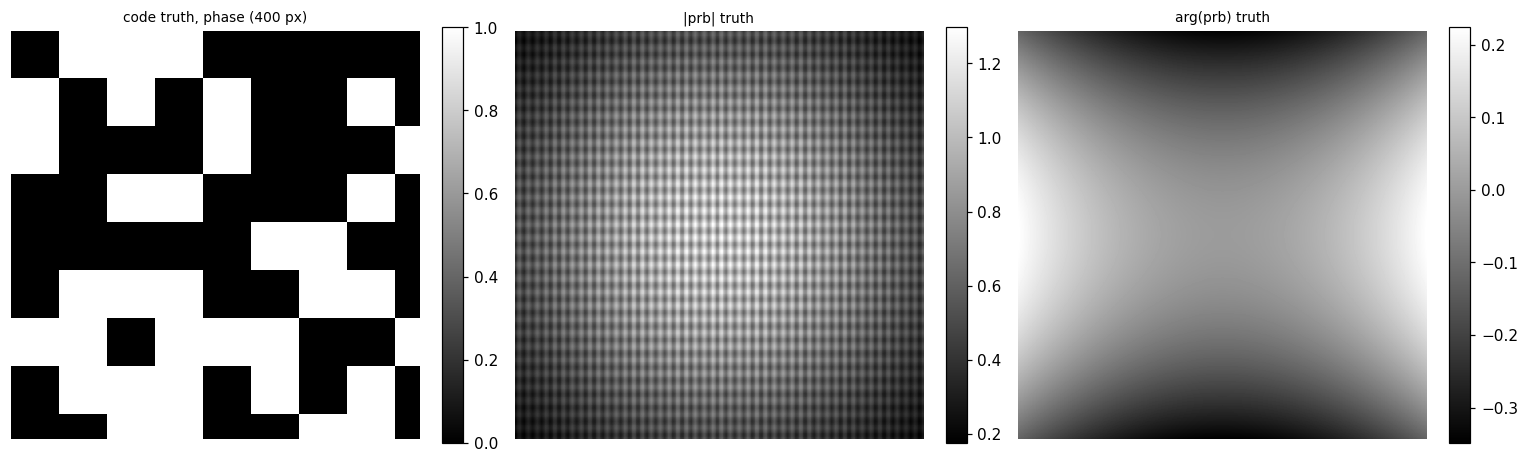

In [2]:
rng = np.random.default_rng(SEED)

# --- aperture: binary gold, |t| <= 1 by construction -----------------------------------------
blocks = NPSI // FEAT + 1
mask = rng.random((blocks, blocks)) < 0.5
mask = np.kron(mask, np.ones((FEAT, FEAT), bool))[:NPSI, :NPSI]
code_true = np.exp(1j * AU_PHASE * mask - AU_ATTEN * mask).astype('complex64')

# --- probe: smooth envelope x line artefacts x slow phase ------------------------------------
y, x = np.mgrid[:N, :N] - N / 2 + .5
env  = np.exp(-(y**2 + x**2) / (2 * (0.42 * N)**2))
lines = 1 + 0.18 * np.sin(2 * np.pi * x / 11.0) + 0.12 * np.sin(2 * np.pi * y / 17.0)
prb_true = (env * lines * np.exp(1j * (0.9 * (x / N)**2 - 1.4 * (y / N)**2))).astype('complex64')

# --- scan positions --------------------------------------------------------------------------
g = np.linspace(-SPAN, SPAN, NSCAN)
pos_true = np.stack(np.meshgrid(g, g, indexing='ij'), -1).reshape(-1, 2).astype('float32')
pos_true += rng.uniform(-0.5, 0.5, pos_true.shape).astype('float32')   # sub-pixel, as in reality
NPOS = len(pos_true)

print(f'code {code_true.shape}  |t| in [{np.abs(code_true).min():.4f}, {np.abs(code_true).max():.4f}]'
      f'   (<= 1 everywhere: it is a passive absorber)')
print(f'prb  {prb_true.shape}   {NPOS} positions, span +-{SPAN} px')

fig, ax = plt.subplots(1, 3, figsize=(14, 4.4))
for a, im, t in ((ax[0], np.angle(code_true[:400, :400]), 'code truth, phase (400 px)'),
                 (ax[1], np.abs(prb_true), '|prb| truth'),
                 (ax[2], np.angle(prb_true), 'arg(prb) truth')):
    h = a.imshow(im, cmap='gray'); a.set_title(t, fontsize=9); a.axis('off')
    fig.colorbar(h, ax=a, fraction=0.046)
plt.tight_layout(); plt.show()

## Simulate the NFP data, with the PSF

`data = K_sigma( |D_nfp(prb * code_window(pos))|^2 )`, the same forward model `RecNFPCoded`
uses, plus the detector blur it does not model. Noiseless on purpose -- we are isolating the
PSF, and noise would only add a second explanation for any residue.

In [3]:
from holotomocupy.shift_fft_code import ShiftFFTCode, window_pad

pad_y, pad_x = window_pad(N, N, 0.125)
sh = ShiftFFTCode(N, N + 2*pad_x, N, N + 2*pad_y, nchunk=1,
                  pad=(pad_y, pad_x), code_shape=(NPSI, NPSI))
m1 = sh.unit_mag(1)
Dnfp = Propagation(N, N, 1, 1, WAVELEN, VOX_NFP, [DIST_NFP])
_, taps_true = psf_taps(PSF_TRUE)

code_g = cp.asarray(code_true); prb_g = cp.asarray(prb_true)
off_all = np.round(pos_true).astype('int32')

def nfp_frame(k, taps):
    r = cp.asarray(pos_true[k:k+1]); o = cp.asarray(off_all[k:k+1])
    w = sh.S(code_g, r, m1, o)[0]
    I = cp.abs(Dnfp.D(prb_g * w, 0)) ** 2
    return I if taps is None else psf_blur(I, taps)

data = np.stack([cp.asnumpy(nfp_frame(k, taps_true)) for k in range(NPOS)]).astype('float32')
sharp0 = cp.asnumpy(nfp_frame(0, None))
print(f'data {data.shape}  mean {data.mean():.4f}')
print(f'PSF changes frame 0 by {np.abs(data[0]-sharp0).max()/sharp0.max()*100:.2f}% peak, '
      f'{np.sqrt(((data[0]-sharp0)**2).mean())/sharp0.mean()*100:.2f}% rms')

data (36, 512, 512)  mean 0.4077
PSF changes frame 0 by 19.94% peak, 11.38% rms


/home/beams0/CEKMEKCI/Desktop/holotomocupy/src/holotomocupy/propagation.py:44: UserWarning: nvcc not found (NVCC='nvcc'). Set NVCC env var or add nvcc to PATH. Falling back to cuPy FFT.
  self._use_cufftdx = cufftdx_available()


## Diagnostic: what does the PSF actually do to the data?

If it is a small perturbation here, it cannot be a large effect downstream, and the whole
hypothesis is in trouble before we start.

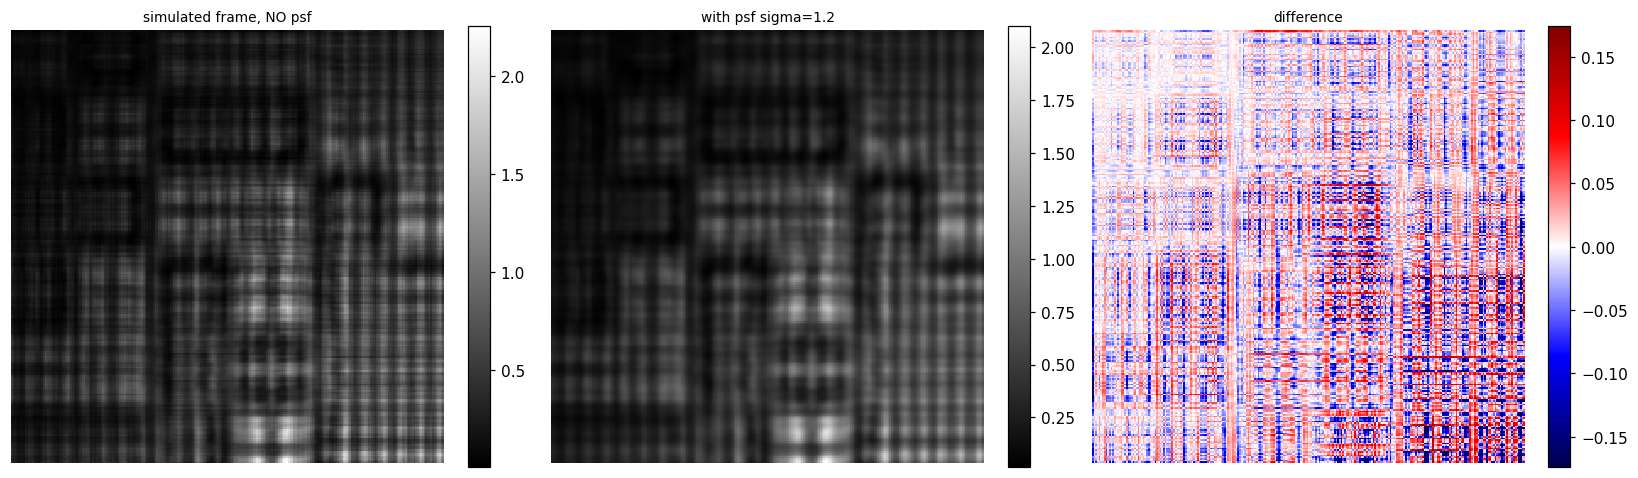

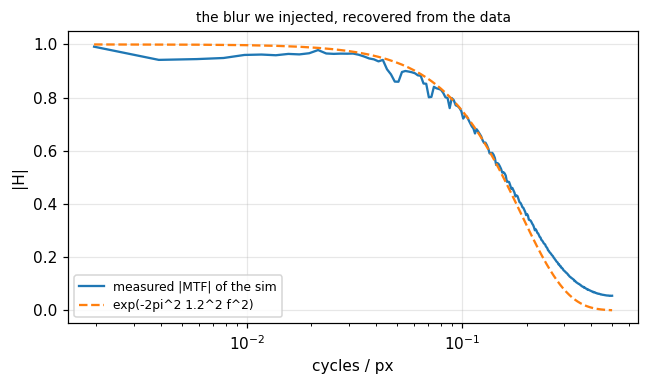

In [4]:
d = data[0] - sharp0
fig, ax = plt.subplots(1, 3, figsize=(15, 4.4))
v = np.percentile(np.abs(d), 99.5)
for a, im, t, kw in ((ax[0], sharp0[:256, :256], 'simulated frame, NO psf', dict(cmap='gray')),
                     (ax[1], data[0][:256, :256], f'with psf sigma={PSF_TRUE}', dict(cmap='gray')),
                     (ax[2], d[:256, :256], 'difference', dict(cmap='seismic', vmin=-v, vmax=v))):
    h = a.imshow(im, **kw); a.set_title(t, fontsize=9); a.axis('off')
    fig.colorbar(h, ax=a, fraction=0.046)
plt.tight_layout(); plt.show()

f = np.fft.rfftfreq(N)
P = lambda a: np.abs(np.fft.rfft(a - a.mean(), axis=-1))**2
ps, pb = P(sharp0).mean(0), P(data[0]).mean(0)
plt.figure(figsize=(6, 3.6))
plt.semilogx(f[1:], np.sqrt(pb[1:]/ps[1:]), label='measured |MTF| of the sim')
plt.semilogx(f[1:], np.exp(-2*np.pi**2*PSF_TRUE**2*f[1:]**2), '--', label=f'exp(-2pi^2 {PSF_TRUE}^2 f^2)')
plt.xlabel('cycles / px'); plt.ylabel('|H|'); plt.legend(fontsize=8); plt.grid(alpha=.3)
plt.title('the blur we injected, recovered from the data', fontsize=9); plt.tight_layout(); plt.show()

## Reconstruct twice

Arm A is the bug: `psf_sigma = 0`, the pipeline as it stands. Arm B is the control:
`psf_sigma = PSF_TRUE`, the model matching how the data was made. Everything else identical,
and both start cold exactly as `step0.py` does.

In [5]:
import os, tempfile
comm = MPI.COMM_WORLD

def run(psf_sigma, label):
    out = tempfile.mkdtemp(prefix=f'sim_{label}_')
    cl = RecNFPCoded(SimpleNamespace(
        energy=ENERGY, detector_pixelsize=DET_PX, focustodetectordistance=FDD, z1=Z1C,
        ntheta=NPOS, nz=N, n=N, nzobj=NPSI, nobj=NPSI,
        rho=[1.0, 2.0, 0.5], niter=NITER, nchunk=4,
        checkpoint_step=-1, error_step=32, start_iter=0,
        psf_sigma=psf_sigma, model='amplitude',
        estimate_rho=False, rho_estimate_niter=16, rho_trial_error_step=-1,
        pos_pad_frac=0.125, path_out=out, shift_type='fft', comm=comm))
    cl.vars['proj'][:] = 0            # cold start, as step0.py
    cl.vars['prb'][:]  = 1
    cl.vars['pos'][:]  = cp.asarray(pos_true[cl.st_theta:cl.end_theta])
    for i in range(cl.local_ntheta):
        cl.data[i] = data[cl.st_theta + i]
    v = cl.BH()
    code_r = cp.asnumpy(cp.exp(1j * v['proj'])).astype('complex64')
    prb_r  = cp.asnumpy(v['prb']).astype('complex64')
    del cl; cp.get_default_memory_pool().free_all_blocks()
    return code_r, prb_r

code_A, prb_A = run(0.0,      'A_nopsf')     # the bug
code_B, prb_B = run(PSF_TRUE, 'B_psf')       # the control
print('done')

2026-11-20 21:37:57 [rank=0] Initial err=2.07011e-01
2026-11-20 21:37:57 [rank=0]   pos err y: [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]
2026-11-20 21:37:57 [rank=0]   pos err x: [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]
2026-11-20 21:37:57 [rank=0] iter=0: 0.1939sec err=1.48388e-02
2026-11-20 21:37:57 [rank=0]   pos err y: [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]
2026-11-20 21:37:57 [rank=0]   pos err x: [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]
2026-11-20 21:38:00 [rank=0] iter=32: 2.6749sec err=2.20529e-04
2026-11-20 21:38:00 [rank=0]   pos err y: [ 0.0378, -0.1359, -0.0804

## Diagnostic: is the recovered aperture physical?

`|t| <= 1` for a passive absorber. On the real data, switching the PSF on inside step0 drove
`|code|` to 2.29 because the solve became an unconstrained deconvolution. If that happens here
too, arm B is not a usable control and we have learned that the runaway is intrinsic rather
than something about the real data.

truth        |t| in [0.8607, 1.0000]
A  psf=0     |t| in [0.5197, 1.7532]   <-- NON-PHYSICAL, |t| > 1
B  psf=1.2   |t| in [0.4248, 2.1428]   <-- NON-PHYSICAL, |t| > 1


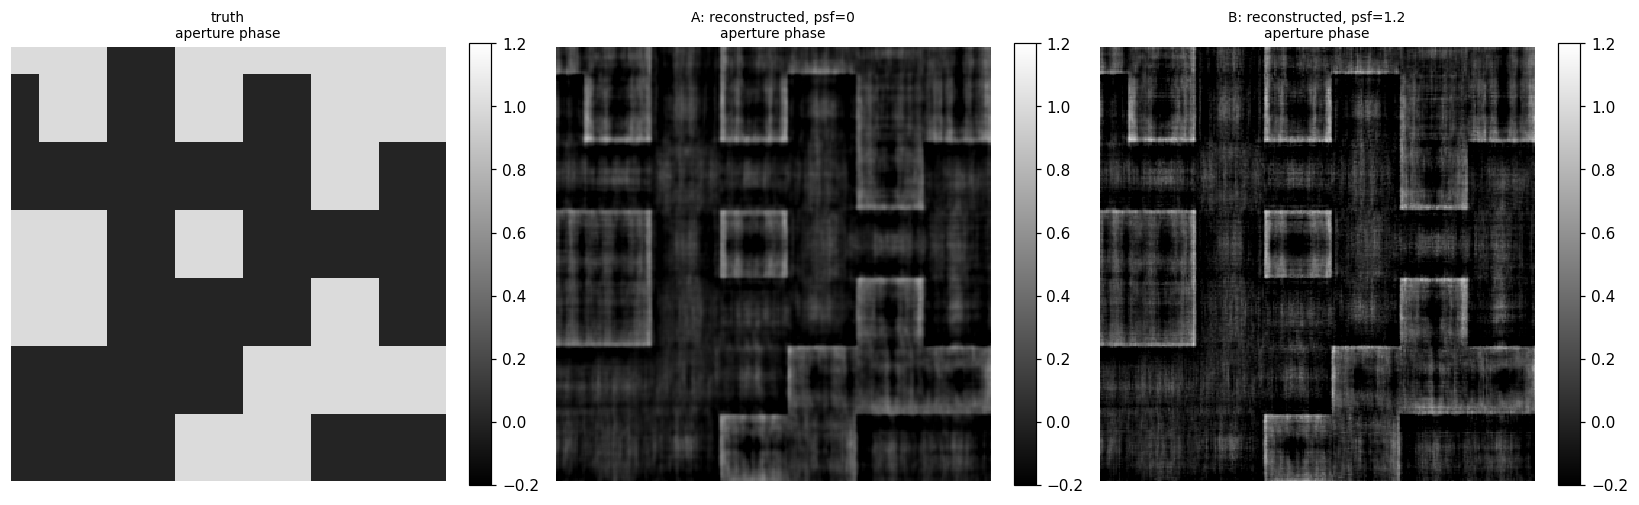

In [6]:
for nm, c in (('truth', code_true), ('A  psf=0', code_A), (f'B  psf={PSF_TRUE}', code_B)):
    a = np.abs(c)
    print(f'{nm:12s} |t| in [{a.min():.4f}, {a.max():.4f}]'
          + ('   <-- NON-PHYSICAL, |t| > 1' if a.max() > 1.01 else ''))

fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
s = slice(NPSI//2 - 150, NPSI//2 + 150)
for a, c, t in ((ax[0], code_true, 'truth'), (ax[1], code_A, 'A: reconstructed, psf=0'),
                (ax[2], code_B, f'B: reconstructed, psf={PSF_TRUE}')):
    h = a.imshow(np.angle(c[s, s]), cmap='gray', vmin=-0.2, vmax=1.2)
    a.set_title(f'{t}\naperture phase', fontsize=9); a.axis('off')
    fig.colorbar(h, ax=a, fraction=0.046)
plt.tight_layout(); plt.show()

## The actual test: carry each into an HT flat field

`pref = |D( D_code( prb * code_window ) )|^2` at the HT geometry, blurred by the true PSF to make
the "measurement", and compared against the same model built from each reconstruction. This is
the step5 division, with the sample removed so nothing else can contaminate it.

The truth arm is the floor -- it shows what perfect inputs would leave.

           arm  rms(ratio-1)  ratio mean
         truth       0.16039     1.03673
      A  psf=0       0.13592     1.00547
    B  psf=1.2       1.66398     1.10555


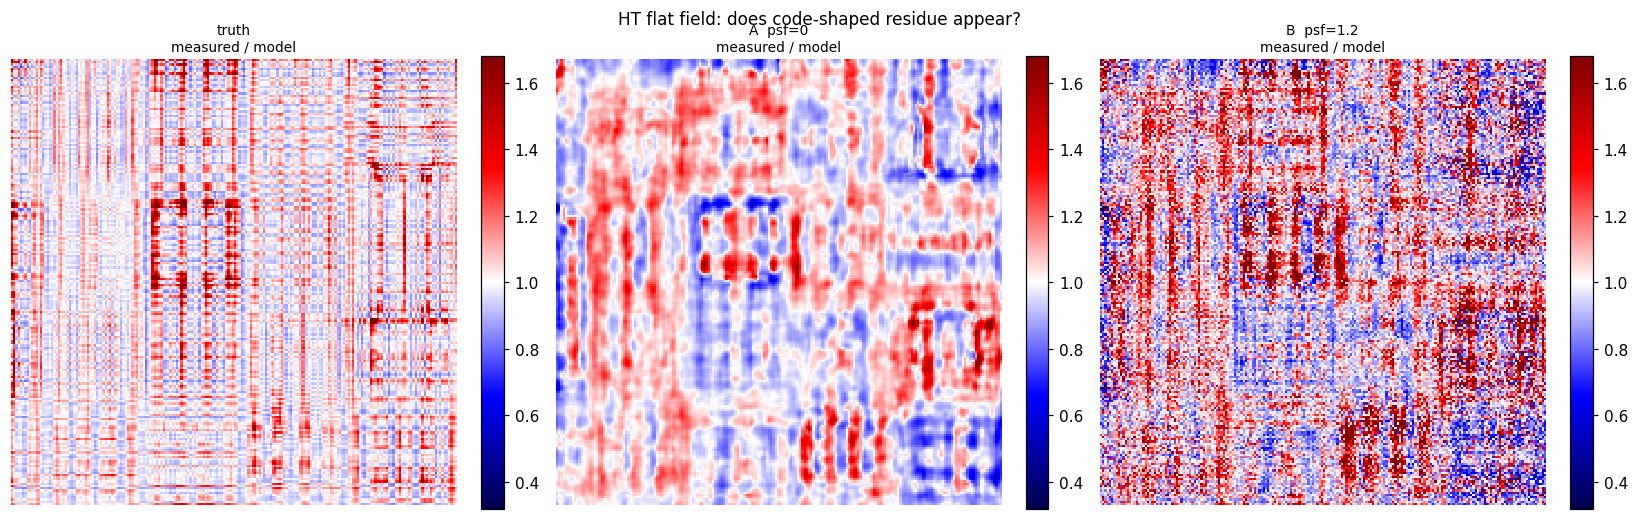

In [7]:
Dht   = Propagation(N, N, 1, 1, WAVELEN, VOX_HT, [DIST_HT])
Dcode = Propagation(N, N, 1, 1, WAVELEN, VOX_HT, [DIST_CODE])
c0 = NPSI // 2

def ht_flat(code_c, prb_c, taps):
    w = cp.asarray(code_c[c0 - N//2:c0 + N//2, c0 - N//2:c0 + N//2])
    I = cp.abs(Dht.D(Dcode.D(cp.asarray(prb_c) * w, 0), 0)) ** 2
    return cp.asnumpy(I if taps is None else psf_blur(I, taps))

pref_meas = ht_flat(code_true, prb_true, taps_true)      # what the detector would record
arms = [('truth', ht_flat(code_true, prb_true, None)),
        ('A  psf=0', ht_flat(code_A, prb_A, None)),
        (f'B  psf={PSF_TRUE}', ht_flat(code_B, prb_B, None))]

C = 48
c_ = (slice(C, N-C), slice(C, N-C))
print(f'{"arm":>14} {"rms(ratio-1)":>13} {"ratio mean":>11}')
for nm, mod in arms:
    r = (pref_meas / (mod + 1e-9))[c_]
    print(f'{nm:>14} {np.sqrt(((r-1)**2).mean()):13.5f} {r.mean():11.5f}')

fig, ax = plt.subplots(1, 3, figsize=(15, 4.8))
r0 = (pref_meas / (arms[0][1] + 1e-9))
v = max(0.02, float(np.percentile(np.abs(r0[c_] - 1), 99.5)))
for a, (nm, mod) in zip(ax, arms):
    h = a.imshow((pref_meas / (mod + 1e-9))[160:360, 160:360], cmap='seismic', vmin=1-v, vmax=1+v)
    a.set_title(f'{nm}\nmeasured / model', fontsize=9); a.axis('off')
    fig.colorbar(h, ax=a, fraction=0.046)
plt.suptitle('HT flat field: does code-shaped residue appear?', fontsize=11)
plt.tight_layout(); plt.show()

## Diagnostic: does code residue appear, and only in arm A?

Read the three panels against each other, not in isolation.

**truth** is the floor. Any structure here is discretisation, not a finding.

**A minus truth** is the effect of reconstructing without the PSF. If A shows code-shaped
residue that truth does not, an unmodelled detector PSF is *sufficient* to produce what we see
on AtomiumS2_coded.

**B** says whether modelling it is the cure. If B is as clean as truth, the fix is to put the
PSF in step0. If B is also dirty, or `|code| > 1` in the diagnostic above, then even the correct
PSF cannot be recovered without constraining the solve, and that is the real problem.

One thing this simulation deliberately cannot tell you. It is noiseless, so it isolates the PSF
and says nothing about whether the effect survives at your actual noise level.